# Milestone 2 – ResNet-18 on BIWI (forward / away)
**Screen Privacy Through Head Orientation · DMET 901**

This notebook covers the four Milestone 2 points:
1. **Run the model** chosen in Milestone 1 (ResNet-18) on the dataset chosen in Milestone 1 (BIWI face crops).
2. **Experimental setup**: preprocessing, hyperparameters and training settings.
3. **Results** and discussion.
4. **Proposed improvement** (proposed here, run in Milestone 3).

**How to run (Google Colab):** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.
The data is downloaded automatically. Training takes a few minutes; the download takes longest.

## 1. Setup and data download
Same sources as Milestone 1: FSA-Net face crops (Google Drive) and HeadPose+ angle files (GitHub). Files are only downloaded if they are missing.

In [1]:
import copy, json, subprocess, time, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torchvision.models import ResNet18_Weights, resnet18

DATA = Path("../data") if Path("../data").exists() else Path("data")
DATA.mkdir(exist_ok=True)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

if not (DATA / "BIWI_noTrack.npz").exists():          # ~1.4 GB zip, we keep one 160 MB file
    try:
        import gdown
    except ImportError:
        subprocess.run(["pip", "-q", "install", "gdown"], check=True); import gdown
    gdown.download(id="1j6GMx33DCcbUOS8J3NHZ-BMHgk7H-oC_", output=str(DATA / "fsanet_data.zip"))
    with zipfile.ZipFile(DATA / "fsanet_data.zip") as z:
        name = next(n for n in z.namelist() if n.endswith("BIWI_noTrack.npz"))
        (DATA / "BIWI_noTrack.npz").write_bytes(z.read(name))
if not (DATA / "headposeplus").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/kuhnkeF/headposeplus", str(DATA / "headposeplus")], check=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

Downloading...
From (original): https://drive.google.com/uc?id=1j6GMx33DCcbUOS8J3NHZ-BMHgk7H-oC_
From (redirected): https://drive.google.com/uc?id=1j6GMx33DCcbUOS8J3NHZ-BMHgk7H-oC_&confirm=t&uuid=43748f70-c097-4246-89aa-943ab1d0864c
To: /content/data/fsanet_data.zip
100%|██████████| 1.39G/1.39G [00:21<00:00, 64.9MB/s]


PyTorch 2.14.1+cu130 | device: Tesla T4


## 2. Run configuration
Every setting of the run is in this one dictionary. These follow the Milestone 1 plan; none were tuned on the test set.

In [2]:
CFG = dict(
    seed=42,
    threshold_deg=20,            # forward if |yaw| <= 20 and |pitch| <= 20
    input_size=224,              # 64x64 crops are enlarged to 224x224
    batch_size=64,
    optimizer="Adam",
    stage1_epochs=5,  stage1_lr=1e-3,    # stage 1: backbone frozen, train only the new 2-class layer
    stage2_epochs=10, stage2_lr=1e-4,    # stage 2: also fine-tune layer4, smaller learning rate
    loss="weighted cross-entropy",       # class weights from training counts only
    augmentation="none",
    model_selection="best validation macro-F1",
)
# Same person-level split as Milestone 1 (12 / 4 / 4 people, seed 42), written as BIWI recording numbers.
# BIWI has 24 recordings of 20 people; 4 people were recorded twice, and both their recordings stay in one split.
SEQ_TO_PERSON = {1: "F01", 2: "F02", 3: "F03", 4: "F04", 5: "F05", 6: "F06", 7: "M01", 8: "M02", 9: "M03", 10: "M04",
                 11: "M05", 12: "M06", 13: "M07", 14: "M08", 15: "F03", 16: "M09", 17: "M10", 18: "F05", 19: "M11",
                 20: "M12", 21: "F02", 22: "M01", 23: "M13", 24: "M14"}
VAL_SEQS  = [6, 9, 16, 19]
TEST_SEQS = [1, 2, 17, 20, 21]
CLASSES = ["away", "forward"]            # class 0 = away, class 1 = forward

torch.manual_seed(CFG["seed"]); np.random.seed(CFG["seed"])
for k, v in CFG.items():
    print(f"{k:16} {v}")

seed             42
threshold_deg    20
input_size       224
batch_size       64
optimizer        Adam
stage1_epochs    5
stage1_lr        0.001
stage2_epochs    10
stage2_lr        0.0001
loss             weighted cross-entropy
augmentation     none
model_selection  best validation macro-F1


## 3. Data: load, label, split
- Images: `BIWI_noTrack.npz` (13,219 face crops, 64 × 64, stored as BGR).
- Angles: calibrated pitch and yaw from HeadPose+ (`Biwi_plus.npz`), matched to the crops by file name.
- Label: **forward** if |yaw| ≤ 20° and |pitch| ≤ 20°, otherwise **away**.
- Split: by person, so no person (and no near-identical video frame) appears in two sets.

In [3]:
crops = np.load(DATA / "BIWI_noTrack.npz")
images = crops["image"][..., ::-1].copy()                 # BGR -> RGB, shape (N, 64, 64, 3), uint8

hpp = DATA / "headposeplus" / "data"
fsa, plus = np.load(hpp / "Biwi_FSA-Net.npz"), np.load(hpp / "Biwi_plus.npz")
row = {name: i for i, name in enumerate(plus["images"])}
match = np.array([row[name] for name in fsa["images"]])   # crop i  ->  row in Biwi_plus
pitch, yaw = plus["pyr"][match, 0], plus["pyr"][match, 1]   # calibrated angles, "pyr" rotation order (as in Milestone 1)
seq = np.array([int(name[:2]) for name in fsa["images"]]) # recording number 1..24

# Check that the crops and the file-name list are in the same order: their (uncalibrated) angles must be identical
assert len(images) == len(fsa["images"]) == 13219
assert np.abs(crops["pose"] - fsa["ypr"]).max() < 1e-6
print("Crops and file names are in the same order.")

T = CFG["threshold_deg"]
y = ((np.abs(yaw) <= T) & (np.abs(pitch) <= T)).astype(np.int64)      # 1 = forward, 0 = away

split = np.where(np.isin(seq, TEST_SEQS), "test", np.where(np.isin(seq, VAL_SEQS), "val", "train"))
idx = {s: np.where(split == s)[0] for s in ("train", "val", "test")}

people = {s: sorted({SEQ_TO_PERSON[q] for q in np.unique(seq[i])}) for s, i in idx.items()}
assert not (set(people["train"]) & set(people["val"]) or set(people["train"]) & set(people["test"]) or set(people["val"]) & set(people["test"]))
print(f"\n{'split':6} {'people':>6} {'images':>7} {'forward':>8} {'away':>6} {'forward %':>10}   who")
for s, i in idx.items():
    print(f"{s:6} {len(people[s]):>6} {len(i):>7,} {y[i].sum():>8,} {(1 - y[i]).sum():>6,} {y[i].mean():>10.1%}   {' '.join(people[s])}")
# Must equal the Milestone 1 table
assert [(len(i), int(y[i].sum())) for i in idx.values()] == [(8933, 2554), (2257, 892), (2029, 824)]
print("Counts match Milestone 1.")

Crops and file names are in the same order.

split  people  images  forward   away  forward %   who
train      12   8,933    2,554  6,379      28.6%   F03 F04 F05 M01 M02 M04 M05 M06 M07 M08 M13 M14
val         4   2,257      892  1,365      39.5%   F06 M03 M09 M11
test        4   2,029      824  1,205      40.6%   F01 F02 M10 M12
Counts match Milestone 1.


## 4. Preprocessing
1. BGR → RGB (done above).
2. Scale pixels from 0–255 to 0–1.
3. Resize 64 × 64 → 224 × 224 (bilinear). This is the size ResNet-18 was pretrained on; it adds no detail.
4. Normalise with the ImageNet mean and standard deviation, as the pretrained weights expect.

No augmentation is used in this baseline run. The whole dataset is small (about 160 MB), so it is kept on the GPU and preprocessed there batch by batch.

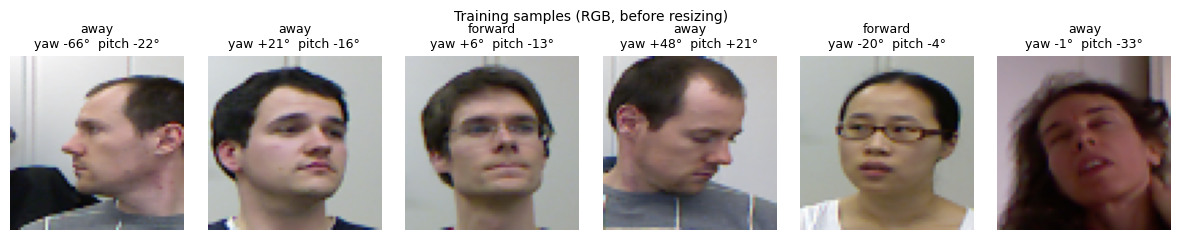

In [4]:
X = torch.from_numpy(images).to(device)                   # uint8, (N, 64, 64, 3)
Y = torch.from_numpy(y).to(device)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def preprocess(batch_uint8):
    x = batch_uint8.permute(0, 3, 1, 2).float() / 255.0
    x = F.interpolate(x, size=CFG["input_size"], mode="bilinear", align_corners=False)
    return (x - MEAN) / STD

fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
show = np.random.default_rng(0).choice(idx["train"], 6, replace=False)
for ax, i in zip(axes, show):
    ax.imshow(images[i]); ax.axis("off")
    ax.set_title(f"{CLASSES[y[i]]}\nyaw {yaw[i]:+.0f}°  pitch {pitch[i]:+.0f}°", fontsize=9)
plt.suptitle("Training samples (RGB, before resizing)", fontsize=10); plt.tight_layout(); plt.show()

## 5. Model and training
- **Model:** torchvision ResNet-18 with ImageNet weights. The 1000-class output layer is replaced by a new 2-class layer (away / forward).
- **Stage 1:** the pretrained backbone is frozen; only the new layer is trained.
- **Stage 2:** the last residual block (`layer4`) is unfrozen and fine-tuned together with the new layer, with a 10× smaller learning rate.
- **Loss:** cross-entropy with class weights `N / (2 · n_class)` from the training set, so mistakes on the rarer *forward* class cost more.
- **Model selection:** after every epoch we measure macro-F1 on the validation people and keep the best weights. The test people are not touched during training.

In [5]:
model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(device)

n_train = np.bincount(y[idx["train"]], minlength=2)
class_weights = torch.tensor(len(idx["train"]) / (2 * n_train), dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
print("Class weights  away: %.3f  forward: %.3f" % tuple(class_weights.tolist()))

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler(enabled=use_amp)
gen = torch.Generator(device="cpu").manual_seed(CFG["seed"])

def set_stage(stage):
    """Choose which layers learn. Frozen layers stay in eval mode so their BatchNorm statistics do not change."""
    for p in model.parameters():
        p.requires_grad = False
    trainable = [model.fc] + ([model.layer4] if stage == 2 else [])
    for m in trainable:
        for p in m.parameters():
            p.requires_grad = True
    params = [p for p in model.parameters() if p.requires_grad]
    print(f"Stage {stage}: {sum(p.numel() for p in params):,} of {sum(p.numel() for p in model.parameters()):,} parameters are trained")
    return trainable, torch.optim.Adam(params, lr=CFG[f"stage{stage}_lr"])

def train_epoch(trainable, optimizer):
    model.eval()
    for m in trainable:
        m.train()
    ids = torch.from_numpy(idx["train"])[torch.randperm(len(idx["train"]), generator=gen)].to(device)
    loss_sum, preds = 0.0, []
    for b in ids.split(CFG["batch_size"]):
        with torch.autocast(device.type, enabled=use_amp):
            out = model(preprocess(X[b]))
            loss = criterion(out, Y[b])
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        loss_sum += loss.item() * len(b); preds.append(out.argmax(1))
    return loss_sum / len(ids), f1_score(Y[ids].cpu().numpy(), torch.cat(preds).cpu().numpy(), average="macro")

@torch.no_grad()
def predict(name):
    """Returns loss, predicted class and P(forward) for one split."""
    model.eval()
    ids = torch.from_numpy(idx[name]).to(device)
    logits = []
    for b in ids.split(256):
        with torch.autocast(device.type, enabled=use_amp):
            logits.append(model(preprocess(X[b])).float())
    logits = torch.cat(logits)
    return criterion(logits, Y[ids]).item(), logits.argmax(1).cpu().numpy(), logits.softmax(1)[:, 1].cpu().numpy()

history, best = [], dict(f1=-1.0)
t0 = time.time()
for stage in (1, 2):
    trainable, optimizer = set_stage(stage)
    for epoch in range(1, CFG[f"stage{stage}_epochs"] + 1):
        tr_loss, tr_f1 = train_epoch(trainable, optimizer)
        va_loss, va_pred, _ = predict("val")
        va_f1 = f1_score(y[idx["val"]], va_pred, average="macro")
        history.append(dict(stage=stage, epoch=epoch, train_loss=tr_loss, train_f1=tr_f1, val_loss=va_loss, val_f1=va_f1))
        flag = ""
        if va_f1 > best["f1"]:
            best = dict(f1=va_f1, stage=stage, epoch=epoch, state=copy.deepcopy(model.state_dict())); flag = "  <- best"
        print(f"  stage {stage} epoch {epoch:2d} | train loss {tr_loss:.3f}  macro-F1 {tr_f1:.3f} | val loss {va_loss:.3f}  macro-F1 {va_f1:.3f}{flag}")
train_minutes = (time.time() - t0) / 60
print(f"\nTraining time: {train_minutes:.1f} min. Best checkpoint: stage {best['stage']}, epoch {best['epoch']} (val macro-F1 {best['f1']:.3f})")
model.load_state_dict(best["state"]); torch.save(best["state"], "resnet18_biwi_best.pt")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 167MB/s]


Class weights  away: 0.700  forward: 1.749
Stage 1: 1,026 of 11,177,538 parameters are trained
  stage 1 epoch  1 | train loss 0.362  macro-F1 0.819 | val loss 0.541  macro-F1 0.727  <- best
  stage 1 epoch  2 | train loss 0.235  macro-F1 0.883 | val loss 0.507  macro-F1 0.756  <- best
  stage 1 epoch  3 | train loss 0.205  macro-F1 0.897 | val loss 0.459  macro-F1 0.784  <- best
  stage 1 epoch  4 | train loss 0.185  macro-F1 0.904 | val loss 0.638  macro-F1 0.744
  stage 1 epoch  5 | train loss 0.175  macro-F1 0.913 | val loss 0.548  macro-F1 0.774
Stage 2: 8,394,754 of 11,177,538 parameters are trained
  stage 2 epoch  1 | train loss 0.166  macro-F1 0.937 | val loss 1.259  macro-F1 0.663
  stage 2 epoch  2 | train loss 0.050  macro-F1 0.978 | val loss 0.617  macro-F1 0.830  <- best
  stage 2 epoch  3 | train loss 0.039  macro-F1 0.983 | val loss 0.727  macro-F1 0.825
  stage 2 epoch  4 | train loss 0.027  macro-F1 0.988 | val loss 1.255  macro-F1 0.745
  stage 2 epoch  5 | train los

## 6. Training curves
The dashed line marks where stage 2 (fine-tuning `layer4`) starts.

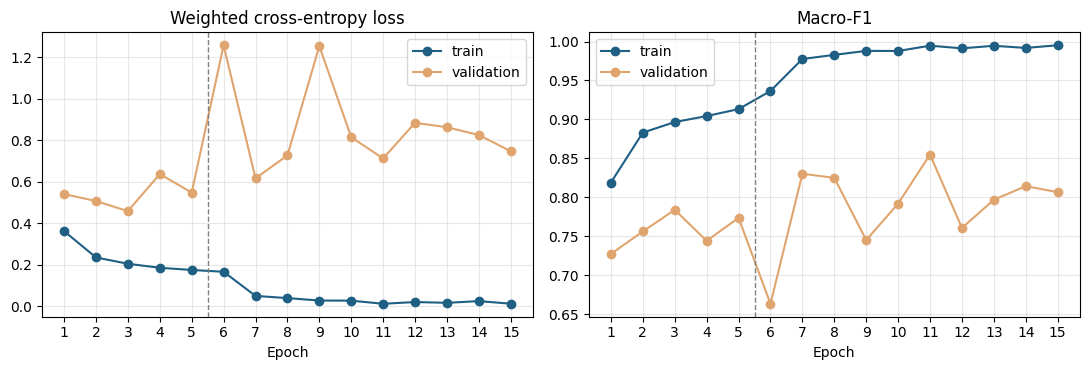

In [6]:
ep = np.arange(1, len(history) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, key, title in zip(axes, ("loss", "f1"), ("Weighted cross-entropy loss", "Macro-F1")):
    ax.plot(ep, [h[f"train_{key}"] for h in history], "o-", color="#1F5F84", label="train")
    ax.plot(ep, [h[f"val_{key}"] for h in history], "o-", color="#E0A56E", label="validation")
    ax.axvline(CFG["stage1_epochs"] + 0.5, color="gray", ls="--", lw=1)
    ax.set_xlabel("Epoch"); ax.set_title(title); ax.set_xticks(ep); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "training_curves.png", dpi=200); plt.show()

## 7. Test results
The best checkpoint is evaluated **once** on the 4 held-out test people, and compared with the always-away baseline from Milestone 1.

                        macro-F1  accuracy
ResNet-18 · train          0.995     99.6%
ResNet-18 · validation     0.855     86.9%
ResNet-18 · TEST           0.891     89.5%
Always-away · TEST         0.373     59.4%

Test set, per class:
              precision    recall  f1-score   support

        away      0.922     0.899     0.910      1205
     forward      0.857     0.888     0.872       824

    accuracy                          0.895      2029
   macro avg      0.889     0.894     0.891      2029
weighted avg      0.895     0.895     0.895      2029



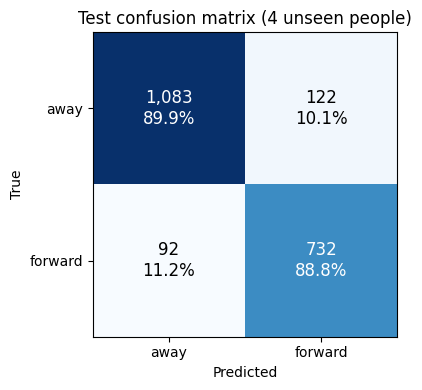

In [7]:
results = {}
for name in ("train", "val", "test"):
    _, pred, prob = predict(name)
    t = y[idx[name]]
    results[name] = dict(macro_f1=f1_score(t, pred, average="macro"), accuracy=accuracy_score(t, pred))
test_true, test_pred, test_prob = t, pred, prob
base_pred = np.zeros_like(test_true)                         # always "away"
results["always_away_test"] = dict(macro_f1=f1_score(test_true, base_pred, average="macro"), accuracy=accuracy_score(test_true, base_pred))

print(f"{'':22} {'macro-F1':>9} {'accuracy':>9}")
for name, label in (("train", "ResNet-18 · train"), ("val", "ResNet-18 · validation"), ("test", "ResNet-18 · TEST"), ("always_away_test", "Always-away · TEST")):
    print(f"{label:22} {results[name]['macro_f1']:>9.3f} {results[name]['accuracy']:>9.1%}")

print("\nTest set, per class:")
print(classification_report(test_true, test_pred, target_names=CLASSES, digits=3))
per_class = classification_report(test_true, test_pred, target_names=CLASSES, output_dict=True)

cm = confusion_matrix(test_true, test_pred)
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n{cm[i, j] / cm[i].sum():.1%}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
ax.set_xticks([0, 1], CLASSES); ax.set_yticks([0, 1], CLASSES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Test confusion matrix (4 unseen people)")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix.png", dpi=200); plt.show()

## 8. Where does the model fail?
Left: every test image by its true head angles; errors are drawn on top. Right: error rate against how far the head is from the 20° line (0° = exactly on the line).

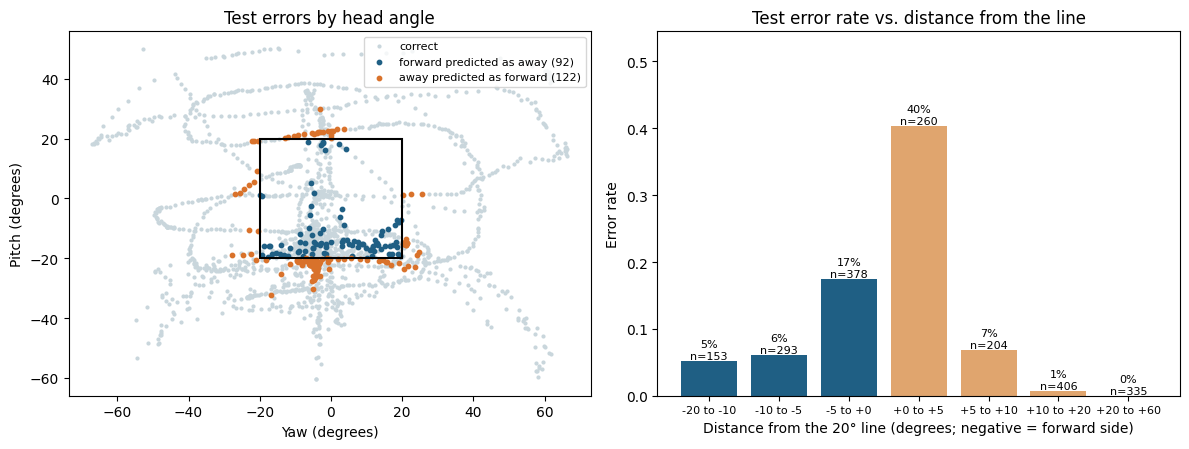

Errors within 5° of the line: 171 of 214 errors (80%); these images are 31% of the test set.
Error rate within 5° of the line: 26.8%   |   further than 5°: 3.1%

Per test person:
  F01:  431 images  accuracy 97.7%  macro-F1 0.963
  F02:  812 images  accuracy 86.3%  macro-F1 0.823
  M10:  315 images  accuracy 85.4%  macro-F1 0.791
  M12:  471 images  accuracy 90.0%  macro-F1 0.893


6102

In [8]:
ti = idx["test"]
wrong = test_pred != test_true
dist = np.maximum(np.abs(yaw[ti]), np.abs(pitch[ti])) - T          # < 0 inside the forward box, > 0 outside

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
ax.scatter(yaw[ti][~wrong], pitch[ti][~wrong], s=4, color="#C9D6DC", label="correct")
fn, fp = wrong & (test_true == 1), wrong & (test_true == 0)
ax.scatter(yaw[ti][fn], pitch[ti][fn], s=10, color="#1F5F84", label=f"forward predicted as away ({fn.sum()})")
ax.scatter(yaw[ti][fp], pitch[ti][fp], s=10, color="#D9722B", label=f"away predicted as forward ({fp.sum()})")
ax.add_patch(plt.Rectangle((-T, -T), 2 * T, 2 * T, fill=False, lw=1.5, color="black"))
ax.set_xlabel("Yaw (degrees)"); ax.set_ylabel("Pitch (degrees)"); ax.set_title("Test errors by head angle"); ax.legend(fontsize=8, loc="upper right")

edges = np.array([-20, -10, -5, 0, 5, 10, 20, 60])
rate, count = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (dist >= lo) & (dist < hi)
    rate.append(wrong[m].mean() if m.any() else 0); count.append(int(m.sum()))
ax = axes[1]
bars = ax.bar(range(len(rate)), rate, color=["#1F5F84"] * 3 + ["#E0A56E"] * 4)
for b, r, c in zip(bars, rate, count):
    ax.text(b.get_x() + b.get_width() / 2, r, f"{r:.0%}\nn={c}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(range(len(rate)), [f"{lo:+d} to {hi:+d}" for lo, hi in zip(edges[:-1], edges[1:])], fontsize=8)
ax.set_xlabel("Distance from the 20° line (degrees; negative = forward side)"); ax.set_ylabel("Error rate")
ax.set_ylim(0, max(rate) * 1.3 + 0.02); ax.set_title("Test error rate vs. distance from the line")
plt.tight_layout(); plt.savefig(FIG / "error_analysis.png", dpi=200); plt.show()

near = np.abs(dist) <= 5
print(f"Errors within 5° of the line: {wrong[near].sum()} of {wrong.sum()} errors ({wrong[near].sum() / wrong.sum():.0%}); these images are {near.mean():.0%} of the test set.")
print(f"Error rate within 5° of the line: {wrong[near].mean():.1%}   |   further than 5°: {wrong[~near].mean():.1%}")

print("\nPer test person:")
per_person = {}
for p in people["test"]:
    m = np.isin(seq[ti], [s for s in TEST_SEQS if SEQ_TO_PERSON[s] == p])
    per_person[p] = dict(images=int(m.sum()), accuracy=accuracy_score(test_true[m], test_pred[m]),
                         macro_f1=f1_score(test_true[m], test_pred[m], average="macro"))
    print(f"  {p}: {m.sum():4d} images  accuracy {per_person[p]['accuracy']:.1%}  macro-F1 {per_person[p]['macro_f1']:.3f}")

summary = dict(config=CFG, device=str(torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu"),
               torch=torch.__version__, train_minutes=round(train_minutes, 2),
               best=dict(stage=best["stage"], epoch=best["epoch"], val_macro_f1=best["f1"]),
               stage1_best_val_f1=max(h["val_f1"] for h in history if h["stage"] == 1),
               class_weights=dict(zip(CLASSES, class_weights.tolist())),
               people=people, counts={s: dict(images=len(i), forward=int(y[i].sum())) for s, i in idx.items()},
               results=results, per_class=per_class, per_person=per_person, test_confusion_matrix=cm.tolist(), history=history,
               errors_within_5deg=int(wrong[near].sum()), errors_total=int(wrong.sum()), near_share=float(near.mean()),
               error_rate_near=float(wrong[near].mean()), error_rate_far=float(wrong[~near].mean()))
Path("ms2_results.json").write_text(json.dumps(summary, indent=2))

## 9. Discussion of the results

**The model learned the task.** On the 4 unseen test people ResNet-18 reaches **macro-F1 0.891** and 89.5% accuracy. Always answering *away* gets macro-F1 0.373 and 59.4% accuracy, so the score does not come from the class imbalance.

| Finding | Evidence from this run |
|---|---|
| Both classes are recognised | away: precision 0.922, recall 0.899 · forward: precision 0.857, recall 0.888 |
| What the errors mean for the app | 92 of 824 forward frames (11.2%) would blur the owner's screen by mistake. 122 of 1,205 away frames (10.1%) would leave the screen visible; this is the privacy-relevant error. |
| Fine-tuning helps | Best validation macro-F1 is 0.784 with only the new layer (stage 1) and 0.855 after fine-tuning `layer4` (stage 2). |
| The model overfits | Train macro-F1 is 0.995, validation 0.855. In stage 2 the training loss falls to about 0.01 while the validation loss stays between 0.6 and 1.3. The network memorises the 12 training people. |
| Training is unstable | In stage 2 the validation macro-F1 jumps between 0.66 and 0.85 from one epoch to the next, so which checkpoint is "best" is partly luck. |
| Errors sit at the 20° line | 171 of 214 test errors (80%) are within 5° of the line, although these images are only 31% of the test set. Error rate: 26.8% within 5°, 3.1% further away. A head at 19° and one at 21° look almost the same but have opposite labels. |
| Results depend on the person | Accuracy per test person ranges from 85.4% (M10) to 97.7% (F01). |

**Limits of this result.** It is one run with one seed and only 4 test people, so the test score is a rough estimate (the test score being above the validation score is within that noise). This milestone trains and evaluates only the head-orientation classifier; YuNet and SFace are pretrained and owner verification is not evaluated here.

## 10. Proposed improvement: data augmentation (to be run in Milestone 3)

This improvement is **proposed only**; it is not part of the run above.

**What:** during training only, each image is randomly mirrored left–right (50% chance) and its brightness and contrast are changed by a random factor between 0.8 and 1.2. Validation and test images stay unchanged.

**Why this one:** the largest problem in the results is overfitting: train macro-F1 0.995 against validation 0.855, with a validation curve that jumps from epoch to epoch. The network memorises the 12 training people. Augmented images are different in every epoch, so they are harder to memorise. They keep their label: our rule uses |yaw|, so a mirrored head is still forward or away, and lighting does not change head direction.

**What we expect to see in Milestone 3:**

| Result from this run | Expected effect of augmentation |
|---|---|
| Train 0.995 vs. validation 0.855 | A smaller gap: lower train score, higher validation score |
| Validation macro-F1 jumps between epochs | A steadier curve, so the chosen checkpoint depends less on luck |
| Test macro-F1 0.891 | Higher macro-F1 on unseen people |
| Accuracy differs a lot between test people | A smaller spread, because the model relies less on each person's lighting and appearance |
| 80% of errors within 5° of the 20° line | Little change: these heads look almost the same as heads on the other side of the line |

**How we will check it:** same split, same settings and seed as this run, with augmentation as the only change. We compare on validation macro-F1, and use the test people once, at the end.